## assignment 1.

ToDo: 
- mathematically prove the boundary of sphere and torus for case a and b. use that as a bounding box. (+ error margin?)

- make a function for generating the needed data

- generate table / figure






In [12]:
import math
import random as random
import numpy as np
import plotly.graph_objects as go
from itertools import combinations, product
import matplotlib.pyplot as plt
import pandas as pd

In [13]:
def sphere_eq(x, y, z, k):
    """ k is the radius of the sphere.
    The function returns True if the point (x, y, z) is on
     or inside the sphere of radius k centred at the origin."""
    return x**2 + y**2 + z**2 <= k**2

def torus_eq(x, y, z, R, r):
    """ R is the distance from the center of the tube to the center of the torus,
    and r is the radius of the tube.
    The function returns True if the point (x, y, z) is on
    or inside the torus with major radius R and minor radius r centred at the origin."""
    return ((x**2 + y**2)**0.5 - R)**2 + z**2 <= r**2

def intersection_eq(x, y, z, k, R, r):
    """Returns True if the point (x, y, z) is inside both the sphere with radius k
    and the torus with major radius R and minor radius r (both centered at the origin)."""
    return sphere_eq(x, y, z, k) and torus_eq(x, y, z, R, r)

def generate_points(n, bounds, rng):
    """Generates n random points within the given bounds.
    bounds is a list of 6 values: [xmin, xmax, ymin, ymax, zmin, zmax].
    rng is a random.Random(seed) generator, so every part has its own reproducible stream."""
    points = []
    for _ in range(n):
        x = rng.uniform(bounds[0], bounds[1])
        y = rng.uniform(bounds[2], bounds[3])
        z = rng.uniform(bounds[4], bounds[5])
        points.append((x, y, z))
    return points

def count_points_in_shape(points, shape_func, *shape_params):
    """Counts how many points from the list are inside the shape defined by shape_func.
    shape_func is a function that takes x, y, z and shape parameters and returns True if the point is inside the shape."""
    count = 0
    for point in points:
        if shape_func(*point, *shape_params):
            count += 1
    return count

def box_volume(bounds):
    """Volume of the box [xmin, xmax, ymin, ymax, zmin, zmax]."""
    return (bounds[1] - bounds[0]) * (bounds[3] - bounds[2]) * (bounds[5] - bounds[4])

def estimate_volume(count, total_points, bounds):
    """Estimates the volume of a shape based on the count of points inside it, total points generated, and the bounding box."""
    return box_volume(bounds) * (count / total_points)

def standard_error(count, total_points, bounds):
    """Standard error of the volume estimate: V_box * sqrt(f * (1 - f) / n), with f the fraction of points inside."""
    f = count / total_points
    return box_volume(bounds) * math.sqrt(f * (1 - f) / total_points)


def reference_volume(k, R, r, z_center=0.0, num_z=400001):
    """Independent 1D numerical-integration check (not a Monte Carlo estimate).

    At height z, sphere and torus overlap in a circular annulus with
    inner radius rho_in and outer radius rho_out. Integrate its area over z.
    Here x_center = y_center = 0, as in all three assignment geometries.
    """
    zlo = max(-k, z_center - r)
    zhi = min(k, z_center + r)
    if zlo >= zhi:
        return 0.0
    z = np.linspace(zlo, zhi, num_z)
    half_width = np.sqrt(np.clip(r**2 - (z - z_center)**2, 0, None))
    rho_in = np.maximum(0, R - half_width)
    rho_out = np.minimum(np.sqrt(np.clip(k**2 - z**2, 0, None)), R + half_width)
    area = np.pi * np.clip(rho_out**2 - rho_in**2, 0, None)
    return float(np.trapezoid(area, z))


n = 100000  # Number of random points to generate

# Bounding box B: |x|, |y| <= k = 1 inside the sphere and |z| <= r <= 0.5 inside the torus
bounds_B = [-1, 1, -1, 1, -0.5, 0.5]

cases = {"a": (1, 0.75, 0.4), "b": (1, 0.5, 0.5)}  # case: (k, R, r)
rng_part1 = random.Random(20261105)  # one generator for part 1; each case gets its own fresh points

reference_volumes = {case: reference_volume(k, R, r) for case, (k, R, r) in cases.items()}
reference_off_center = reference_volume(1, 0.75, 0.4, z_center=0.1)
print('Reference volumes (independent 1D integration):',
      ', '.join(f'{c}: {v:.6f}' for c, v in reference_volumes.items()),
      f', off-centre: {reference_off_center:.6f}')

results_uniform = {}
running_uniform = {}  # cumulative estimates for the convergence figure
for case, (k, R, r) in cases.items():
    points = generate_points(n, bounds_B, rng_part1)
    # Same yes/no test used by the hit count, now retained at each sample size.
    hits = np.fromiter((intersection_eq(*point, k, R, r) for point in points),
                       dtype=np.int8, count=n)
    count = int(hits.sum())
    running_uniform[case] = box_volume(bounds_B) * np.cumsum(hits) / np.arange(1, n + 1)
    volume = estimate_volume(count, n, bounds_B)
    error = standard_error(count, n, bounds_B)
    results_uniform[case] = (volume, error)
    print(f"case {case}: count = {count} of {n} points are in the intersection")
    print(f"case {case}: estimated volume of the intersection: {volume:.4f} ± {1.96 * error:.4f} (95% confidence interval)")

print(f"exact volume case b: 2*pi^2*R*r^2 = {2 * math.pi**2 * 0.5 * 0.5**2:.4f}")

Reference volumes (independent 1D integration): a: 1.856056, b: 2.467401 , off-centre: 1.828380
case a: count = 46429 of 100000 points are in the intersection
case a: estimated volume of the intersection: 1.8572 ± 0.0124 (95% confidence interval)
case b: count = 61753 of 100000 points are in the intersection
case b: estimated volume of the intersection: 2.4701 ± 0.0120 (95% confidence interval)
exact volume case b: 2*pi^2*R*r^2 = 2.4674


In [14]:
def sphere_eq(x, y, z, k):
    """ k is the radius of the sphere.
    The function returns True if the point (x, y, z) is on
     or inside the sphere of radius k centred at the origin."""
    return x**2 + y**2 + z**2 <= k**2

def torus_eq(x, y, z, R, r):
    """ R is the distance from the center of the tube to the center of the torus,
    and r is the radius of the tube.
    The function returns True if the point (x, y, z) is on
    or inside the torus with major radius R and minor radius r centred at the origin."""
    return ((x**2 + y**2)**0.5 - R)**2 + z**2 <= r**2

def intersection_eq(x, y, z, k, R, r):
    """Returns True if the point (x, y, z) is inside both the sphere with radius k
    and the torus with major radius R and minor radius r (both centered at the origin)."""
    return sphere_eq(x, y, z, k) and torus_eq(x, y, z, R, r)

def generate_points(n, bounds, rng):
    """Generates n random points within the given bounds.
    bounds is a list of 6 values: [xmin, xmax, ymin, ymax, zmin, zmax].
    rng is a random.Random(seed) generator, so every part has its own reproducible stream."""
    points = []
    for _ in range(n):
        x = rng.uniform(bounds[0], bounds[1])
        y = rng.uniform(bounds[2], bounds[3])
        z = rng.uniform(bounds[4], bounds[5])
        points.append((x, y, z))
    return points

def count_points_in_shape(points, shape_func, *shape_params):
    """Counts how many points from the list are inside the shape defined by shape_func.
    shape_func is a function that takes x, y, z and shape parameters and returns True if the point is inside the shape."""
    count = 0
    for point in points:
        if shape_func(*point, *shape_params):
            count += 1
    return count

def box_volume(bounds):
    """Volume of the box [xmin, xmax, ymin, ymax, zmin, zmax]."""
    return (bounds[1] - bounds[0]) * (bounds[3] - bounds[2]) * (bounds[5] - bounds[4])

def estimate_volume(count, total_points, bounds):
    """Estimates the volume of a shape based on the count of points inside it, total points generated, and the bounding box."""
    return box_volume(bounds) * (count / total_points)

def standard_error(count, total_points, bounds):
    """Standard error of the volume estimate: V_box * sqrt(f * (1 - f) / n), with f the fraction of points inside."""
    f = count / total_points
    return box_volume(bounds) * math.sqrt(f * (1 - f) / total_points)


def reference_volume(k, R, r, z_center=0.0, num_z=400001):
    """Independent 1D numerical-integration check (not a Monte Carlo estimate).

    At height z, sphere and torus overlap in a circular annulus with
    inner radius rho_in and outer radius rho_out. Integrate its area over z.
    Here x_center = y_center = 0, as in all three assignment geometries.
    """
    zlo = max(-k, z_center - r)
    zhi = min(k, z_center + r)
    if zlo >= zhi:
        return 0.0
    z = np.linspace(zlo, zhi, num_z)
    half_width = np.sqrt(np.clip(r**2 - (z - z_center)**2, 0, None))
    rho_in = np.maximum(0, R - half_width)
    rho_out = np.minimum(np.sqrt(np.clip(k**2 - z**2, 0, None)), R + half_width)
    area = np.pi * np.clip(rho_out**2 - rho_in**2, 0, None)
    return float(np.trapezoid(area, z))


n = 100000  # Number of random points to generate

# Bounding box B: |x|, |y| <= k = 1 inside the sphere and |z| <= r <= 0.5 inside the torus
bounds_B = [-1, 1, -1, 1, -0.5, 0.5]

cases = {"a": (1, 0.75, 0.4), "b": (1, 0.5, 0.5)}  # case: (k, R, r)
rng_part1 = random.Random(20261105)  # one generator for part 1; each case gets its own fresh points

reference_volumes = {case: reference_volume(k, R, r) for case, (k, R, r) in cases.items()}
reference_off_center = reference_volume(1, 0.75, 0.4, z_center=0.1)
print('Reference volumes (independent 1D integration):',
      ', '.join(f'{c}: {v:.6f}' for c, v in reference_volumes.items()),
      f', off-centre: {reference_off_center:.6f}')

results_uniform = {}
running_uniform = {}  # cumulative estimates for the convergence figure
for case, (k, R, r) in cases.items():
    points = generate_points(n, bounds_B, rng_part1)
    # Same yes/no test used by the hit count, now retained at each sample size.
    hits = np.fromiter((intersection_eq(*point, k, R, r) for point in points),
                       dtype=np.int8, count=n)
    count = int(hits.sum())
    running_uniform[case] = box_volume(bounds_B) * np.cumsum(hits) / np.arange(1, n + 1)
    volume = estimate_volume(count, n, bounds_B)
    error = standard_error(count, n, bounds_B)
    results_uniform[case] = (volume, error)
    print(f"case {case}: count = {count} of {n} points are in the intersection")
    print(f"case {case}: estimated volume of the intersection: {volume:.4f} ± {1.96 * error:.4f} (95% confidence interval)")

print(f"exact volume case b: 2*pi^2*R*r^2 = {2 * math.pi**2 * 0.5 * 0.5**2:.4f}")

Reference volumes (independent 1D integration): a: 1.856056, b: 2.467401 , off-centre: 1.828380
case a: count = 46429 of 100000 points are in the intersection
case a: estimated volume of the intersection: 1.8572 ± 0.0124 (95% confidence interval)
case b: count = 61753 of 100000 points are in the intersection
case b: estimated volume of the intersection: 2.4701 ± 0.0120 (95% confidence interval)
exact volume case b: 2*pi^2*R*r^2 = 2.4674


Figure 1 — geometry ($x$–$z$ slice at $y=0$), box $B$ dashed, $S$ dotted.

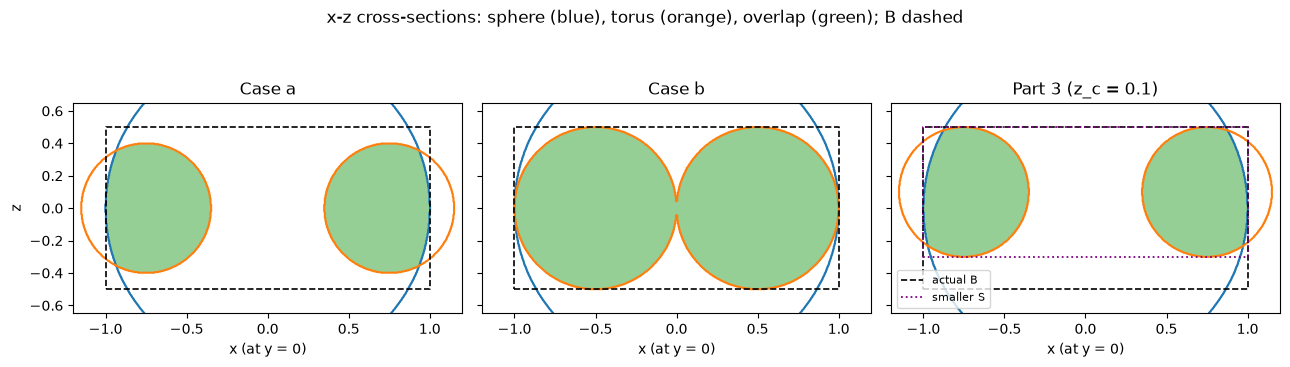

In [15]:
# True Cartesian x-z cross-sections (y=0) so the dashed rectangle is the
# actual box B used in the simulations. S is dotted for the shifted-torus panel.
x_grid, z_grid = np.meshgrid(np.linspace(-1.2, 1.2, 600),
                             np.linspace(-0.65, 0.65, 360))
panels = [("Case a", 1, 0.75, 0.4, 0.0),
          ("Case b", 1, 0.5, 0.5, 0.0),
          ("Part 3 (z_c = 0.1)", 1, 0.75, 0.4, 0.1)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for i, (ax, (title, k, R, r, zc)) in enumerate(zip(axes, panels)):
    sph = x_grid**2 + z_grid**2 <= k**2
    tor = (np.abs(x_grid) - R)**2 + (z_grid - zc)**2 <= r**2
    ax.contourf(x_grid, z_grid, (sph & tor).astype(float), [0.5, 1.5],
                colors=["tab:green"], alpha=0.5)
    ax.contour(x_grid, z_grid, sph.astype(float), [0.5], colors="tab:blue")
    ax.contour(x_grid, z_grid, tor.astype(float), [0.5], colors="tab:orange")
    ax.plot([-1, 1, 1, -1, -1], [-0.5, -0.5, 0.5, 0.5, -0.5],
            "k--", lw=1.2, label="actual B")
    if i == 2:
        ax.plot([-1, 1, 1, -1, -1], [-0.3, -0.3, 0.5, 0.5, -0.3],
                color="purple", ls=":", lw=1.3, label="smaller S")
        ax.legend(loc="lower left", fontsize=8)
    ax.set(title=title, xlabel="x (at y = 0)", xlim=(-1.2, 1.2),
           ylim=(-0.65, 0.65), aspect="equal")
axes[0].set_ylabel("z")
fig.suptitle("x-z cross-sections: sphere (blue), torus (orange), overlap (green); B dashed")
plt.tight_layout()
plt.savefig("fig1_geometry.png", dpi=200)
plt.show()

Figure 2 — running estimate with 95% CI band (same Part 1 samples).

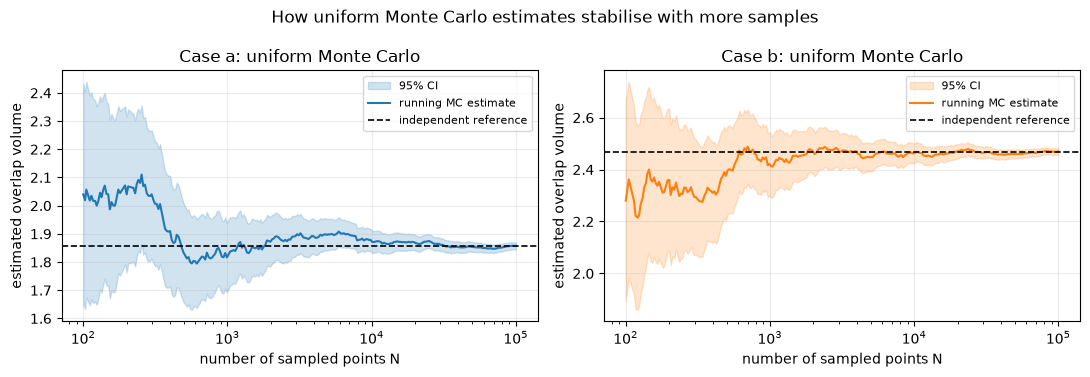

In [16]:
# Uses exactly the samples generated in Part 1, rather than a new unrelated experiment.
steps = np.unique(np.round(np.geomspace(100, n, 260)).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, case, color in zip(axes, cases, ["tab:blue", "tab:orange"]):
    run = running_uniform[case][steps - 1]
    half = 1.96 * box_volume(bounds_B) * np.sqrt((run / box_volume(bounds_B)) * (1 - run / box_volume(bounds_B)) / steps)
    ax.fill_between(steps, run - half, run + half, color=color, alpha=0.2, label="95% CI")
    ax.plot(steps, run, color=color, lw=1.5, label="running MC estimate")
    ax.axhline(reference_volumes[case], color="black", ls="--", lw=1.2,
               label="independent reference")
    ax.set(xscale="log", xlabel="number of sampled points N", ylabel="estimated overlap volume",
           title=f"Case {case}: uniform Monte Carlo")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("How uniform Monte Carlo estimates stabilise with more samples")
fig.tight_layout()
plt.savefig("fig2_convergence.png", dpi=200, bbox_inches="tight")
plt.show()

Three sequences (different $X_0$, 1000 discarded iterations) rescaled to $B$.

In [17]:
# 2. generate deterministic points in the bounding box
#  and check if they are in the intersection of the sphere and torus

def logistic_sequence(x0, n, m=3.8, burn_in=1000):
    """Returns n values of X_{n+1} = m * X_n * (1 - X_n), starting from x0.
    The first burn_in values are thrown away so the starting value has less influence."""
    x = x0
    for _ in range(burn_in):
        x = m * x * (1 - x)
    seq = []
    for _ in range(n):
        x = m * x * (1 - x)
        seq.append(x)
    return seq


n = 100000
x0 = 0.5
y0 = 0.1
z0 = 0.2

xs = logistic_sequence(x0, n)
ys = logistic_sequence(y0, n)
zs = logistic_sequence(z0, n)

# rescale from (0, 1) to the box B
xmin, xmax, ymin, ymax, zmin, zmax = bounds_B
logistic_points = [(xmin + (xmax - xmin) * u, ymin + (ymax - ymin) * v, zmin + (zmax - zmin) * w)
                   for u, v, w in zip(xs, ys, zs)]

results_logistic = {}
for case, (k, R, r) in cases.items():
    count = count_points_in_shape(logistic_points, intersection_eq, k, R, r)
    volume = estimate_volume(count, n, bounds_B)
    # Do NOT use the independent-uniform binomial standard error here.
    results_logistic[case] = volume
    print(f"case {case} deterministic: count = {count} of {n} points are in the intersection")
    print(f"case {case} deterministic: estimated volume of the intersection: {volume:.4f} "
          f"(no valid CI: the points are not independent and not uniform)")

case a deterministic: count = 53160 of 100000 points are in the intersection
case a deterministic: estimated volume of the intersection: 2.1264 (no valid CI: the points are not independent and not uniform)
case b deterministic: count = 66784 of 100000 points are in the intersection
case b deterministic: estimated volume of the intersection: 2.6714 (no valid CI: the points are not independent and not uniform)


30 uniform runs vs 30 logistic runs (different $X_0$ triples), compared with the reference. The last column is descriptive only for the logistic map.

In [18]:
REPS = 30
x0s = np.random.default_rng(2).uniform(0.05, 0.95, size=(REPS, 3))
rng_uni = np.random.default_rng(3)
lo, hi = np.array(bounds_B[::2]), np.array(bounds_B[1::2])
estimates = {"uniform": {c: [] for c in cases}, "logistic": {c: [] for c in cases}}
for j in range(REPS):
    P_uni = rng_uni.uniform(lo, hi, size=(n, 3))
    P_log = lo + (hi - lo) * np.array([logistic_sequence(x0, n) for x0 in x0s[j]]).T
    for case, (k, R, r) in cases.items():
        for name, P in (("uniform", P_uni), ("logistic", P_log)):
            x, y, z = P.T
            count = np.sum(sphere_eq(x, y, z, k) & torus_eq(x, y, z, R, r))
            estimates[name][case].append(estimate_volume(count, n, bounds_B))

# SE of the mean = sd / sqrt(REPS); error / SE_mean tells whether a mean error is larger than chance
print(f'{"case":<5}{"sampler":<10}{"mean":>9}{"sd across":>11}{"SE of":>9}{"mean error":>12}{"error /":>9}')
print(f'{"":<5}{"":<10}{"":>9}{"runs":>11}{"mean":>9}{"vs ref":>12}{"SE mean":>9}')
for case in cases:
    ref = reference_volumes[case]
    for name in estimates:
        e = np.array(estimates[name][case])
        se_mean = e.std(ddof=1) / np.sqrt(REPS)
        print(f"{case:<5}{name:<10}{e.mean():9.4f}{e.std(ddof=1):11.4f}{se_mean:9.4f}"
              f"{e.mean() - ref:12.4f}{(e.mean() - ref) / se_mean:9.1f}")
print(f"\nrange of logistic values: [{min(xs):.3f}, {max(xs):.3f}]   theory: [{3.8**2/4*(1-3.8/4):.3f}, {3.8/4:.3f}]")

case sampler        mean  sd across    SE of  mean error  error /
                               runs     mean      vs ref  SE mean
a    uniform      1.8578     0.0049   0.0009      0.0017      1.9
a    logistic     2.1163     0.0065   0.0012      0.2603    218.7
b    uniform      2.4693     0.0044   0.0008      0.0019      2.4
b    logistic     2.6632     0.0039   0.0007      0.1958    274.8

range of logistic values: [0.181, 0.950]   theory: [0.181, 0.950]


Figure 3 — histogram, lag plot, estimates over 30 runs.

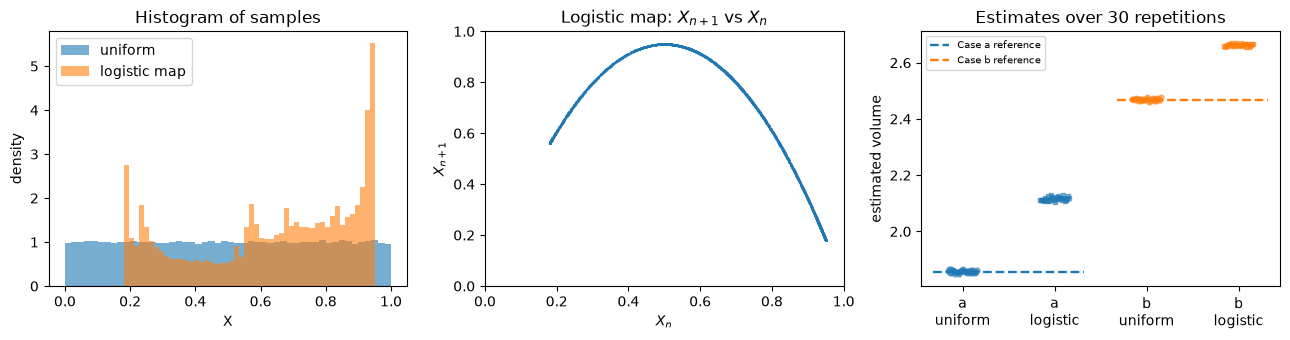

In [19]:
# Logistic values are not uniform and not independent
u = np.random.default_rng(4).uniform(size=n)
v = np.array(xs)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(u, bins=50, density=True, alpha=0.6, label="uniform")
axes[0].hist(v, bins=50, density=True, alpha=0.6, label="logistic map")
axes[0].set(title="Histogram of samples", xlabel="X", ylabel="density"); axes[0].legend()
axes[1].plot(v[:-1][:3000], v[1:][:3000], ".", ms=1)
axes[1].set(title="Logistic map: $X_{n+1}$ vs $X_n$", xlabel="$X_n$", ylabel="$X_{n+1}$", xlim=(0, 1), ylim=(0, 1))
# Compare the empirical estimates with the independently integrated true volume.
positions = np.arange(4)
labels = ["a\nuniform", "a\nlogistic", "b\nuniform", "b\nlogistic"]
colors = {"a": "tab:blue", "b": "tab:orange"}
for i, (case, method) in enumerate([("a", "uniform"), ("a", "logistic"),
                                      ("b", "uniform"), ("b", "logistic")]):
    values = np.asarray(estimates[method][case])
    offsets = np.linspace(-0.16, 0.16, len(values))
    axes[2].scatter(i + offsets, values, s=12, alpha=0.55,
                    color=colors[case], marker="o" if method == "uniform" else "s")
for case, low, high in [("a", -0.32, 1.32), ("b", 1.68, 3.32)]:
    axes[2].hlines(reference_volumes[case], low, high, colors=colors[case],
                   linestyles="--", linewidth=1.7,
                   label=f"Case {case} reference" )
axes[2].set_xticks(positions, labels)
axes[2].set(xlim=(-0.45, 3.45), title=f"Estimates over {REPS} repetitions", ylabel="estimated volume")
axes[2].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig("fig3_logistic.png", dpi=200); plt.show()

The logistic values lie only in $[0.18,0.95]$ with a non-uniform density, and each value is a fixed function of the previous one. The points are neither uniform nor independent, so $V_BH/N$ is biased (≈ +0.26 and +0.20), more samples do not help, and the binomial SE does not apply. The small spread over $X_0$ hides the bias.

In [20]:
# 3

def off_center_torus(X, Y, Z, R, r, center):
    """R is the distance from the center of the tube to the center of the torus,
    and r is the radius of the tube.
    The function returns True if the point (X, Y, Z) is on
    or inside the torus with major radius R and minor radius r centred at the specified center."""
    xc, yc, zc = center
    return (((X - xc)**2 + (Y - yc)**2)**0.5 - R)**2 + (Z - zc)**2 <= r**2


def intersection_off_center(x, y, z, k, R, r, center):
    return sphere_eq(x, y, z, k) and off_center_torus(x, y, z, R, r, center)

center = (0, 0, 0.1)
points = generate_points(n, bounds_B, random.Random(20261106))
count = count_points_in_shape(points, intersection_off_center, 1, 0.75, 0.4, center)
V3, se3 = estimate_volume(count, n, bounds_B), standard_error(count, n, bounds_B)
print(f"off-centre: count = {count} of {n}, estimated volume: {V3:.4f} ± {1.96 * se3:.4f} (approx. 95% CI half-width)")
print(f"independent integration reference: {reference_off_center:.6f}; observed error: {V3 - reference_off_center:+.6f}")
# The shift changes the *true* geometric overlap, not merely the sampled output.
delta_mc = V3 - results_uniform["a"][0]
delta_ref = reference_off_center - reference_volumes["a"]
se_difference = math.hypot(se3, results_uniform["a"][1])  # different random streams
print(f"Change from centred Case 1a to shifted torus: MC {delta_mc:+.5f} "
      f"± {1.96 * se_difference:.5f} (approx. 95% half-width for difference)")
print(f"Independent geometric change: {delta_ref:+.5f} "
      f"({100 * delta_ref / reference_volumes['a']:.2f}% relative)")

off-centre: count = 45525 of 100000, estimated volume: 1.8210 ± 0.0123 (approx. 95% CI half-width)
independent integration reference: 1.828380; observed error: -0.007380
Change from centred Case 1a to shifted torus: MC -0.03616 ± 0.01747 (approx. 95% half-width for difference)
Independent geometric change: -0.02768 (-1.49% relative)


    p    naive  E[naive]  weighted    SE_w
 0.00   2.2883    2.2855    1.8307  0.0050
 0.25   2.1666    2.1712    1.8245  0.0053
 0.50   2.0612    2.0569    1.8322  0.0056
 0.75   1.9438    1.9427    1.8295  0.0060
 1.00   1.8244    1.8284    1.8244  0.0063


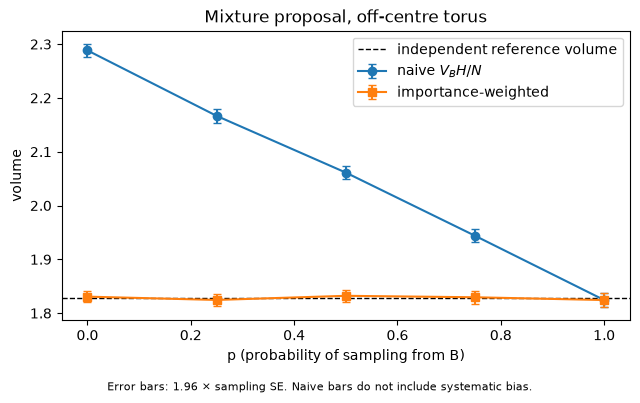

In [21]:
bounds_S = [-1, 1, -1, 1, -0.3, 0.5]
lo_S, hi_S = np.array(bounds_S[::2]), np.array(bounds_S[1::2])
rows = []
for i, p in enumerate([0, 0.25, 0.5, 0.75, 1]):
    rng_mix = np.random.default_rng(10 + i)  # independent run for each p
    from_B = rng_mix.random(n) < p
    # Draw only the points actually needed from each box.
    P = np.empty((n, 3))
    P[from_B] = rng_mix.uniform(lo, hi, size=(from_B.sum(), 3))
    P[~from_B] = rng_mix.uniform(lo_S, hi_S, size=((~from_B).sum(), 3))
    x, y, z = P.T
    hit = sphere_eq(x, y, z, 1) & off_center_torus(x, y, z, 0.75, 0.4, center)
    in_S = np.all((P >= lo_S) & (P <= hi_S), axis=1)
    q = p / box_volume(bounds_B) + (1 - p) / box_volume(bounds_S) * in_S
    naive, naive_se = estimate_volume(hit.sum(), n, bounds_B), standard_error(hit.sum(), n, bounds_B)
    w = hit / q
    expected_naive = reference_off_center * (p + (1 - p) * box_volume(bounds_B) / box_volume(bounds_S))
    rows.append((p, naive, naive_se, w.mean(), w.std(ddof=1) / np.sqrt(n), expected_naive))

print(f'{"p":>5}{"naive":>9}{"E[naive]":>10}{"weighted":>10}{"SE_w":>8}')
for p, nv, nse, wv, wse, ex in rows:
    print(f"{p:5.2f}{nv:9.4f}{ex:10.4f}{wv:10.4f}{wse:8.4f}")

res = np.array(rows)
plt.figure(figsize=(6.5, 4))
plt.errorbar(res[:, 0], res[:, 1], yerr=1.96 * res[:, 2], fmt="o-", capsize=3, label="naive $V_B H/N$")
plt.errorbar(res[:, 0], res[:, 3], yerr=1.96 * res[:, 4], fmt="s-", capsize=3, label="importance-weighted")
plt.axhline(reference_off_center, color="k", ls="--", lw=1,
            label="independent reference volume")
plt.xlabel("p (probability of sampling from B)"); plt.ylabel("volume"); plt.legend()
plt.title("Mixture proposal, off-centre torus")
plt.figtext(0.5, 0.01, "Error bars: 1.96 × sampling SE. Naive bars do not include systematic bias.",
            ha="center", fontsize=8)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig("fig4_mixture.png", dpi=200); plt.show()

The naive estimate is biased upward for $p<1$ because points in $S$ are over-represented (flaw of the mixture without weights); its error bars only show noise around the wrong value. Weighting by $1/q_p$ removes the bias for every $p$. The variance gain is small ($V_S/V_B=0.8$); uniform sampling in $S$ alone ($p=0$) gives the same. If $S$ missed part of the intersection, $p=0$ would be biased and $p>0$ would give large weights.

# Summary

In [22]:
# CI not applicable for logistic and naive mixture rows (biased / not i.i.d. uniform)
summary_rows = []
for case in cases:
    vol, se = results_uniform[case]
    summary_rows.append({
        "Experiment": f"Part 1{case}", "Method": "uniform MC",
        "Estimate": vol, "Reference": reference_volumes[case],
        "Signed error": vol - reference_volumes[case],
        "95% CI half-width": 1.96 * se,
    })
for case in cases:
    mean_logistic = float(np.mean(estimates["logistic"][case]))
    summary_rows.append({
        "Experiment": f"Part 2{case}", "Method": "logistic mean (30 seeds)",
        "Estimate": mean_logistic, "Reference": reference_volumes[case],
        "Signed error": mean_logistic - reference_volumes[case],
        "95% CI half-width": np.nan,  # not applicable for raw logistic sampling
    })
summary_rows.append({
    "Experiment": "Part 3a", "Method": "uniform MC, shifted torus",
    "Estimate": V3, "Reference": reference_off_center,
    "Signed error": V3 - reference_off_center,
    "95% CI half-width": 1.96 * se3,
})
for p, nv, nse, wv, wse, ex in rows:
    if p in (0, 0.5):
        summary_rows.append({"Experiment": "Part 3b", "Method": f"mixture p={p}, naive",
                             "Estimate": nv, "Reference": reference_off_center,
                             "Signed error": nv - reference_off_center, "95% CI half-width": np.nan})
        summary_rows.append({"Experiment": "Part 3b", "Method": f"mixture p={p}, weighted",
                             "Estimate": wv, "Reference": reference_off_center,
                             "Signed error": wv - reference_off_center, "95% CI half-width": 1.96 * wse})
summary = pd.DataFrame(summary_rows)
display(summary.round(5).fillna("not applicable"))

/var/folders/_s/3m5r3tk90cb5vvjhzy5smf0h0000gn/T/ipykernel_9848/1238589868.py:34: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(summary.round(5).fillna("not applicable"))


,Experiment,Method,Estimate,Reference,Signed error,95% CI half-width
0,Part 1a,uniform MC,1.85716,1.85606,0.00110,0.01236
1,Part 1b,uniform MC,2.47012,2.46740,0.00272,0.01205
2,Part 2a,logistic mean (30 seeds),2.11633,1.85606,0.26028,not applicable
3,Part 2b,logistic mean (30 seeds),2.66322,2.46740,0.19581,not applicable
4,Part 3a,"uniform MC, shifted torus",1.82100,1.82838,-0.00738,0.01235
5,Part 3b,"mixture p=0, naive",2.28832,1.82838,0.45994,not applicable
6,Part 3b,"mixture p=0, weighted",1.83066,1.82838,0.00228,0.00981
7,Part 3b,"mixture p=0.5, naive",2.06124,1.82838,0.23286,not applicable
8,Part 3b,"mixture p=0.5, weighted",1.83221,1.82838,0.00383,0.01101


# archive

In [23]:
def tight_bounding_box(k, R, r):
    """A tight box [xmin, xmax, ymin, ymax, zmin, zmax] that contains the intersection of the sphere (radius k)
    and the torus (major radius R, minor radius r), both centered at the origin, assuming R >= r and k > R - r.
    With rho = sqrt(x^2 + y^2) the shapes are two discs in the (rho, z) plane: center (0, 0) with radius k,
    and center (R, 0) with radius r. The box follows from the largest rho and the largest |z| of their overlap."""
    # largest rho, reached at z = 0: the edge of the sphere (k) or the outer edge of the tube (R + r)
    rho_max = min(k, R + r)
    if R**2 + r**2 <= k**2:
        z_max = r  # the top of the tube (R, r) lies inside the sphere
    else:
        rho_cross = (k**2 + R**2 - r**2) / (2 * R)  # rho where the two circles cross
        z_max = math.sqrt(k**2 - rho_cross**2)      # the top of the overlap is that crossing point
    return [-rho_max, rho_max, -rho_max, rho_max, -z_max, z_max]


for name, (k, R, r) in {"case a": (1, 0.75, 0.4), "case b": (1, 0.5, 0.5)}.items():
    print(f"{name}: tight bounding box B* = {tight_bounding_box(k, R, r)}")

case a: tight bounding box B* = [-1, 1, -1, 1, -0.4, 0.4]
case b: tight bounding box B* = [-1, 1, -1, 1, -0.5, 0.5]


Case a: k=1, R=0.75, r=0.4: reference V = 1.8561 | B*: 1.8551 ± 0.0098 | [-1, 1]^3: 1.8426 ± 0.0209 (95% CI)
Case b: k=1, R=0.5, r=0.5: reference V = 2.4674 | B*: 2.4714 ± 0.0120 | [-1, 1]^3: 2.4737 ± 0.0229 (95% CI)


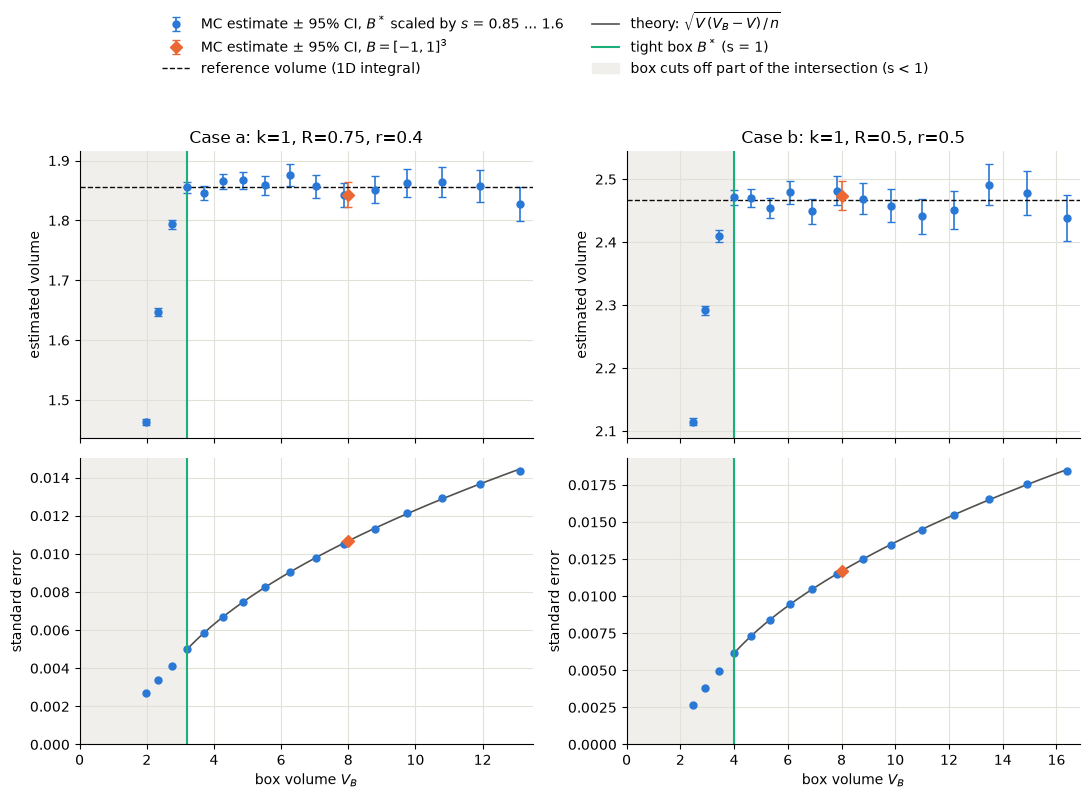

In [24]:
# Estimated volume for different bounding boxes.
# Every box is the tight box B* scaled about its center by a factor s (all side lengths times s):
# s < 1 cuts off part of the intersection, s > 1 only adds empty space.
# The sphere's box [-1, 1]^3 is added for comparison.


# Reuse reference_volume from Part 1: avoids inconsistent reference calculations.

def scaled_box(bounds, s):
    """Box with the same center as bounds and all side lengths multiplied by s."""
    new_bounds = []
    for lo, hi in zip(bounds[::2], bounds[1::2]):
        mid, half = (lo + hi) / 2, s * (hi - lo) / 2
        new_bounds += [mid - half, mid + half]
    return new_bounds


def mc_volume(k, R, r, bounds, n, rng):
    """Uniform Monte Carlo estimate of the intersection volume using the box bounds: (volume, standard error)."""
    x, y, z = rng.uniform(bounds[::2], bounds[1::2], size=(n, 3)).T
    count = int(np.sum(sphere_eq(x, y, z, k) & torus_eq(x, y, z, R, r)))
    return estimate_volume(count, n, bounds), standard_error(count, n, bounds)


rng_box = np.random.default_rng(1)
scales = np.round(np.linspace(0.85, 1.6, 16), 2)
configs = {"Case a: k=1, R=0.75, r=0.4": (1, 0.75, 0.4),
           "Case b: k=1, R=0.5, r=0.5": (1, 0.5, 0.5)}

BLUE, ORANGE, AQUA, INK, MUTED, GRID, SHADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e1e0d9", "#f0efec"
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex="col")

for col, (title, (k, R, r)) in enumerate(configs.items()):
    B_tight = tight_bounding_box(k, R, r)
    B_cube = [-k, k, -k, k, -k, k]
    V_tight, V_cube = box_volume(B_tight), box_volume(B_cube)
    V_boxes = V_tight * scales**3
    est, err = np.array([mc_volume(k, R, r, scaled_box(B_tight, s), n, rng_box) for s in scales]).T
    est_cube, err_cube = mc_volume(k, R, r, B_cube, n, rng_box)
    V_ref = reference_volume(k, R, r)

    i = np.argmin(np.abs(scales - 1))  # s = 1 is the tight box itself
    print(f"{title}: reference V = {V_ref:.4f} | B*: {est[i]:.4f} ± {1.96 * err[i]:.4f} | "
          f"[-1, 1]^3: {est_cube:.4f} ± {1.96 * err_cube:.4f} (95% CI)")

    top, bottom = axes[0, col], axes[1, col]
    mc_points = top.errorbar(V_boxes, est, yerr=1.96 * err, fmt="o", color=BLUE, ms=5, elinewidth=1.2, capsize=3,
                             label=r"MC estimate ± 95% CI, $B^*$ scaled by $s$ = 0.85 ... 1.6")
    cube_point = top.errorbar(V_cube, est_cube, yerr=1.96 * err_cube, fmt="D", color=ORANGE, ms=6, elinewidth=1.2,
                              capsize=3, label=r"MC estimate ± 95% CI, $B = [-1, 1]^3$")
    ref_line = top.axhline(V_ref, color=INK, ls="--", lw=1, label="reference volume (1D integral)")
    top.set(title=title, ylabel="estimated volume")

    V_grid = np.linspace(V_tight, V_boxes.max(), 200)
    theory_line, = bottom.plot(V_grid, np.sqrt(V_ref * (V_grid - V_ref) / n), color=MUTED, lw=1.2,
                               label=r"theory: $\sqrt{V\,(V_B - V)\,/\,n}$")
    bottom.plot(V_boxes, err, "o", color=BLUE, ms=5)
    bottom.plot(V_cube, err_cube, "D", color=ORANGE, ms=6)
    bottom.set(xlabel=r"box volume $V_B$", ylabel="standard error")
    bottom.set_ylim(bottom=0)

    for ax in (top, bottom):
        cut_span = ax.axvspan(0, V_tight, color=SHADE, label="box cuts off part of the intersection (s < 1)")
        tight_line = ax.axvline(V_tight, color=AQUA, lw=1.5, label=r"tight box $B^*$ (s = 1)")
        ax.set_xlim(0, V_boxes.max() * 1.03)
        ax.grid(color=GRID, lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)

fig.legend(handles=[mc_points, cube_point, ref_line, theory_line, tight_line, cut_span],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.savefig("fig5_boxes.png", dpi=200)
plt.show()

In [25]:
def implicit_surface(inside, bounds, h, name, color, opacity, visible=True):
    """Draws the boundary of the region where inside(X, Y, Z) is True.
    bounds = ((xmin, xmax), (ymin, ymax), (zmin, zmax)) is the region to evaluate on,
    h is the grid spacing (smaller = smoother surface but larger output).
    Each grid cell is evaluated at 2x2x2 sub-points and the inside-count is contoured,
    which gives a much smoother surface than contouring a plain True/False grid."""
    axes = [np.arange(lo - 2*h, hi + 2.5*h, h, dtype=np.float32) for lo, hi in bounds]
    X, Y, Z = np.meshgrid(*axes, indexing="ij")
    offsets = (-h/4, h/4)
    counts = sum(inside(X + dx, Y + dy, Z + dz).astype(np.uint8)
                 for dx, dy, dz in product(offsets, repeat=3))  # 0 (outside) .. 8 (inside)
    return go.Isosurface(
        x=X.ravel(), y=Y.ravel(), z=Z.ravel(), value=counts.ravel(),
        isomin=4, isomax=4, surface_count=1,
        caps=dict(x_show=False, y_show=False, z_show=False),
        colorscale=[[0, color], [1, color]], showscale=False, flatshading=False,
        opacity=opacity, name=name, showlegend=True, visible=visible,
        hovertemplate=name + "<br>x=%{x:.2f}, y=%{y:.2f}, z=%{z:.2f}<extra></extra>",
    )


def box_wireframe(bounds, name, color):
    """Draws the 12 edges of the box ((xmin, xmax), (ymin, ymax), (zmin, zmax))."""
    corners = list(product(*bounds))
    xs, ys, zs = [], [], []
    for a, b in combinations(corners, 2):
        if sum(ai != bi for ai, bi in zip(a, b)) == 1:  # corners differ in one coordinate -> edge
            xs += [a[0], b[0], None]
            ys += [a[1], b[1], None]
            zs += [a[2], b[2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", line=dict(color=color, width=5),
                        name=name, hoverinfo="name")


def plot_sphere_torus(k, R, r, torus_center=(0, 0, 0), boxes=None, h=0.06, title=None):
    """Interactive plot of the sphere (sphere_eq) and torus (torus_eq) from the cell above.
    torus_center shifts the torus for the off-center case.
    boxes is a dict {name: ((xmin, xmax), (ymin, ymax), (zmin, zmax))} of bounding boxes to overlay.
    Click legend entries to show/hide shapes; the intersection starts hidden."""
    xc, yc, zc = torus_center

    def sphere(X, Y, Z):
        return sphere_eq(X, Y, Z, k)

    def torus(X, Y, Z):
        return torus_eq(X - xc, Y - yc, Z - zc, R, r)

    sphere_bounds = ((-k, k), (-k, k), (-k, k))
    torus_bounds = ((xc - R - r, xc + R + r), (yc - R - r, yc + R + r), (zc - r, zc + r))
    overlap_bounds = tuple((max(s0, t0), min(s1, t1))
                           for (s0, s1), (t0, t1) in zip(sphere_bounds, torus_bounds))

    traces = [
        implicit_surface(sphere, sphere_bounds, h, f"Sphere (k={k})", "#2a78d6", 0.2),
        implicit_surface(torus, torus_bounds, h, f"Torus (R={R}, r={r})", "#eb6834", 0.85),
        implicit_surface(lambda X, Y, Z: sphere(X, Y, Z) & torus(X, Y, Z), overlap_bounds, h,
                         "Intersection", "#1baf7a", 1.0, visible="legendonly"),
    ]
    box_colors = ["#52514e", "#6250d6", "#e87ba4"]
    for (name, bounds), color in zip((boxes or {}).items(), box_colors):
        traces.append(box_wireframe(bounds, name, color))

    fig = go.Figure(traces)
    fig.update_layout(
        title=title, height=650, margin=dict(l=0, r=0, t=40, b=0),
        legend=dict(x=0.01, y=0.98),
        scene=dict(aspectmode="data", xaxis_title="x", yaxis_title="y", zaxis_title="z"),
    )
    return fig


# Case a, with the box B = [-1, 1]^3
fig = plot_sphere_torus(k=1, R=0.75, r=0.4,
                        boxes={"B = [-1, 1]^3": ((-1, 1), (-1, 1), (-1, 1))},
                        title="Case a: k=1, R=0.75, r=0.4")
fig.show()

# Other cases, e.g.:
# plot_sphere_torus(k=1, R=0.5, r=0.5, boxes={"B": ((-1, 1), (-1, 1), (-1, 1))}, title="Case b").show()
# plot_sphere_torus(k=1, R=0.75, r=0.4, torus_center=(0, 0, 0.1),
#                   boxes={"B": ((-1, 1), (-1, 1), (-1, 1)), "S": ((-1, 1), (-1, 1), (-0.3, 0.5))},
#                   title="Part 3: off-center torus").show()